## DATA ANALYSIS FOR THE ML PROJECT

# Importing and display of the data


In [202]:
%load_ext autoreload
%autoreload 2
import numpy as np
import implementations
from helpers import *
from aux_exploratory_data_analysis import *
from aux_cleaning_functions import *
import csv

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [203]:
x_train, x_test, y_train, train_ids, test_ids = load_csv_data("data")

In [204]:
# We transform the data form (-1,1) to (0,1) 
Y_tr = (y_train + 1) / 2

In [205]:
x_train, x_validation, x_te, y_train, y_validation, y_te = split_data(x_train, Y_tr, ratiotrain=0.7, ratiovalidation=0.15, seed=None)

print (x_train.shape, y_train.shape)
print (x_validation.shape, y_validation.shape)
print (x_te.shape, y_te.shape)

(229694, 321) (229694,)
(49220, 321) (49220,)
(49221, 321) (49221,)


In [206]:
import os

file_path = os.path.join("data", "x_train.csv")

# 1. Read headers from the CSV inside the 'data' folder
with open(file_path, "r") as f:
    headers = f.readline().strip().split(",")

# Get shape dimensions from the 2D NumPy array
num_rows, num_columns = x_train.shape

print(f"Headers: {headers}")
print(f"Number of columns: {num_columns}")
print(f"Number of rows: {num_rows}")

Headers: ['Id', '_STATE', 'FMONTH', 'IDATE', 'IMONTH', 'IDAY', 'IYEAR', 'DISPCODE', 'SEQNO', '_PSU', 'CTELENUM', 'PVTRESD1', 'COLGHOUS', 'STATERES', 'CELLFON3', 'LADULT', 'NUMADULT', 'NUMMEN', 'NUMWOMEN', 'CTELNUM1', 'CELLFON2', 'CADULT', 'PVTRESD2', 'CCLGHOUS', 'CSTATE', 'LANDLINE', 'HHADULT', 'GENHLTH', 'PHYSHLTH', 'MENTHLTH', 'POORHLTH', 'HLTHPLN1', 'PERSDOC2', 'MEDCOST', 'CHECKUP1', 'BPHIGH4', 'BPMEDS', 'BLOODCHO', 'CHOLCHK', 'TOLDHI2', 'CVDSTRK3', 'ASTHMA3', 'ASTHNOW', 'CHCSCNCR', 'CHCOCNCR', 'CHCCOPD1', 'HAVARTH3', 'ADDEPEV2', 'CHCKIDNY', 'DIABETE3', 'DIABAGE2', 'SEX', 'MARITAL', 'EDUCA', 'RENTHOM1', 'NUMHHOL2', 'NUMPHON2', 'CPDEMO1', 'VETERAN3', 'EMPLOY1', 'CHILDREN', 'INCOME2', 'INTERNET', 'WEIGHT2', 'HEIGHT3', 'PREGNANT', 'QLACTLM2', 'USEEQUIP', 'BLIND', 'DECIDE', 'DIFFWALK', 'DIFFDRES', 'DIFFALON', 'SMOKE100', 'SMOKDAY2', 'STOPSMK2', 'LASTSMK2', 'USENOW3', 'ALCDAY5', 'AVEDRNK2', 'DRNK3GE5', 'MAXDRNKS', 'FRUITJU1', 'FRUIT1', 'FVBEANS', 'FVGREEN', 'FVORANG', 'VEGETAB1', 'EXERAN

In [207]:
for row in (x_train[:5]): #Display the first rows of the dataset to get a better understanding of the data.
    print (row)

[3.50000000e+01 1.00000000e+01 1.01120150e+07 1.00000000e+01
 1.10000000e+01 2.01500000e+03 1.10000000e+03 2.01500616e+09
 2.01500616e+09            nan            nan            nan
            nan            nan            nan            nan
            nan            nan 1.00000000e+00 1.00000000e+00
 2.00000000e+00 1.00000000e+00            nan 1.00000000e+00
 2.00000000e+00 1.00000000e+00 2.00000000e+00 8.80000000e+01
 8.80000000e+01            nan 1.00000000e+00 1.00000000e+00
 2.00000000e+00 1.00000000e+00 3.00000000e+00            nan
 1.00000000e+00 1.00000000e+00 2.00000000e+00 2.00000000e+00
 2.00000000e+00            nan 2.00000000e+00 2.00000000e+00
 2.00000000e+00 2.00000000e+00 2.00000000e+00 2.00000000e+00
 3.00000000e+00            nan 2.00000000e+00 3.00000000e+00
 4.00000000e+00 1.00000000e+00            nan            nan
            nan 2.00000000e+00 7.00000000e+00 8.80000000e+01
 7.70000000e+01 2.00000000e+00 1.26000000e+02 5.01000000e+02
            nan 2.000000

# Cleaning of the dataset

Exploring Nans;

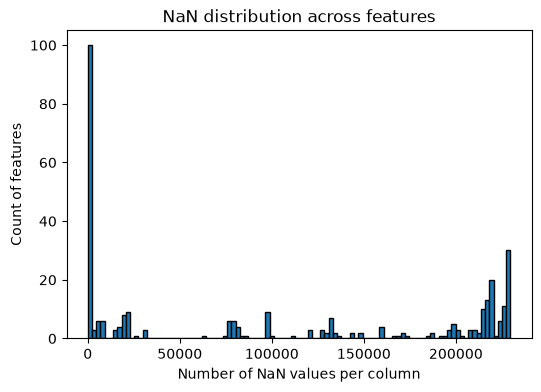

In [208]:
nan_number, nan_pctg = nan_count(x_train ,plot = True)

We can see in our plot that there are aproximately 100 features with 0 Nans and more than 30 that have over 300.000 Nans 

In [209]:
print(f'Percentage of NaN values per column {np.round(nan_pctg)}')

Percentage of NaN values per column [  0.   0.   0.   0.   0.   0.   0.   0.   0.  42.  42. 100.  42.  42.
 100.  42.  43.  43.  58.  58.  58.  58. 100.  58.  58.  59.   0.   0.
   0.  49.   0.   0.   0.   0.   0.  60.   0.  13.  13.   0.   0.  87.
   0.   0.   0.   0.   0.   0.   0.  87.   0.   0.   0.   0.  42.  97.
  42.   0.   0.   0.   1.   1.   1.   1.  85.   2.   2.   3.   3.   3.
   3.   3.   3.  58.  86.  72.   3.   4.  52.  52.  52.   6.   7.   7.
   7.   7.   8.   8.  33.  33.  33.  33.  55.  55.   9.  69.  69.  69.
  70.   9.   9.  57.  57.  10.  10.  74.  74.  81.  81.  93.  93.  93.
  93.  93.  93.  93.  93.  93.  75.  95.  95.  95.  95.  95.  95.  95.
  81.  99.  99.  99. 100.  99.  99.  99.  99.  99.  74.  97.  97.  99.
  97.  97.  91.  94.  91. 100. 100. 100. 100. 100. 100. 100. 100. 100.
 100. 100. 100.  96.  97.  99.  99.  99.  96.  96.  96.  96.  91.  98.
 100.  94.  95.  96.  95.  95.  95.  98.  95.  99.  99.  88.  95.  88.
  91.  91.  99.  99.  99.  99.  99.  99. 

Cleanin Nans; 

In [210]:
keep_mask_nan = remove_nan_feat(x_train, threshold=0.3)
# keep mask of features with less than `threshold` proportion of NaN values

In [211]:
X_clean_nan_tr = x_train[:, keep_mask_nan]
X_clean_nan_val = x_validation[:, keep_mask_nan]
X_clean_nan_te = x_te[:, keep_mask_nan]
X_clean_nan_test = x_test[:, keep_mask_nan]
print (f'Number of features after removing NaN values: {X_clean_nan_tr.shape[1]}')

Number of features after removing NaN values: 144


In [212]:
cat_mask, num_mask = detect_categorical_features(X_clean_nan_tr, max_unique=30)
#cat_mask : np.ndarray of bool Boolean mask of categorical columns.
#num_mask : np.ndarray of bool  Boolean mask of numerical columns.

Some functions to know more about specific columns; 

In [213]:

stats = summarize_basic(X_clean_nan_tr, cat_mask)


#Dictionary containing mean, std, min, max, median, and mode (  )

In [214]:
j = 120 # Which column are we analyzing
show_feature_stats(stats, j) 

Feature 120
  Mean:   2.1042
  Std:    2.5177
  Min:    1.0000
  Max:    9.0000
  Median: 1.0000
  Mode:   1.0


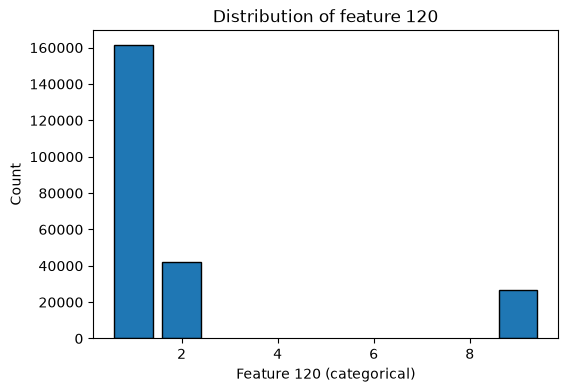

In [215]:
plot_feature_distribution(X_clean_nan_tr, cat_mask, j, bins=30)
# plot of the feature we choose 


Exploring Outliers; 

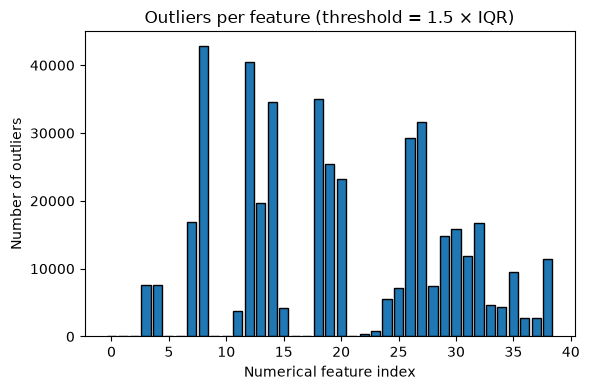

In [216]:
outlier_mask, outlier_counts = detect_outliers(X_clean_nan_tr, num_mask, threshold=1.5, plot=True)
#Detects outliers in numerical features using the IQR method.

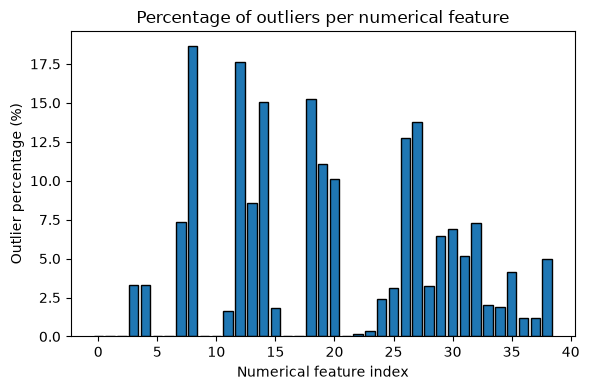

In [217]:
outlier_pctg = summarize_outliers(outlier_mask, num_mask, plot=True)

Cleaning outliers. We can see that the way of treating the data is very conservative as we're choosing to delete those columns in which the percentage of outliers is very big. We could maybe improve such model by applying a box-cox transformation to the columns with a high number of outliers.

In [218]:
keep_mask_out = remove_outliers_feat(X_clean_nan_tr, num_mask, threshold_IQR=1.5, threshold_out=0.3)
X_clean_out_tr = X_clean_nan_tr[:, keep_mask_out]
X_clean_out_val = X_clean_nan_val[:, keep_mask_out]
X_clean_out_te = X_clean_nan_te[:, keep_mask_out]
X_clean_out_test = X_clean_nan_test[:, keep_mask_out]

In [219]:
cat_mask, num_mask = detect_categorical_features(X_clean_nan_tr, max_unique=30)


In [220]:
print(f'Number of categorical columns; {np.sum(cat_mask)} \nNumber of numerical columns {np.sum(num_mask)}')

Number of categorical columns; 105 
Number of numerical columns 39


In [221]:
stats = summarize_basic(X_clean_out_tr, cat_mask)
mean = stats['mean']
std = stats['std']
X_imp_tr, medians_tr = impute_numerical(X_clean_out_tr, num_mask, medians=None, means=None, strategy='medians')
#Imputes NaN values in numerical features with their medians, means, or samples from a normal distribution.
#If predefined medians or means are provided, they are used instead.

X_imp_tr, modes_tr = impute_categorical(X_imp_tr, cat_mask, modes=None)
#Imputes NaN values in categorical features with the mode (most frequent value).
#If predefined modes are provided, they are used instead.



X_imp_val, _ = impute_numerical(X_clean_out_val, num_mask, medians=medians_tr, means=means_tr, strategy='medians')
X_imp_val, _ = impute_categorical(X_imp_val, cat_mask, modes=modes_tr)


X_imp_te, _ = impute_numerical(X_clean_out_te, num_mask, medians=medians_tr, means=means_tr, strategy='medians')
X_imp_te, _ = impute_categorical(X_imp_te, cat_mask, modes=modes_tr)


X_imp_test, _ = impute_numerical(X_clean_out_test, num_mask, medians=medians_tr, means=means_tr, strategy='medians')
X_imp_test, _ = impute_categorical(X_imp_test, cat_mask, modes=modes_tr)


print(np.isnan(X_std_tr).sum(),
      np.isnan(X_std_val).sum(),
      np.isnan(X_std_te).sum(),
      np.isnan(X_std_test).sum())

0 0 0 0


In [222]:
#Now we want to transform the data into a format that can be used by our models. We will use one-hot encoding for categorical features and keep numerical features as they are.

x_train, categories = one_hot_encode(X_imp_tr, cat_mask)

x_val, _ = one_hot_encode(X_imp_val, cat_mask, categories=categories)

x_te, _ = one_hot_encode(X_imp_te, cat_mask, categories=categories)

x_test, _ = one_hot_encode(X_imp_test, cat_mask, categories=categories)

print (x_train.shape, x_val.shape, x_te.shape, x_test.shape)


(229694, 435) (49220, 435) (49221, 435) (109379, 435)


In [223]:
X_std_tr, means_tr, stds_tr= standardize_features(x_train, num_mask, means=None, stds=None)
X_std_val, _, _ = standardize_features(x_val, num_mask, means=means_tr, stds=stds_tr)
X_std_te, _, _ = standardize_features(x_te, num_mask, means=means_tr, stds=stds_tr)
X_std_test, _, _ = standardize_features(x_test, num_mask, means=means_tr, stds=stds_tr)
#Standardizes numerical features (mean 0, std 1).
#Non-numerical (categorical / one-hot) features are left unchanged.

# Studying the colinearity of the data


There are also some funcitons to study correaltaion: 


In [224]:
mask = feature_target_correlation(X_std_tr, y_train, threshold_elimination=0.01)
#Computes Pearson correlation between each feature and the target y
# and returns a boolean mask indicating features with |correlation| above threshold.
corr_matrix = correlation_matrix(X_std_tr)
#Computes the Pearson correlation matrix between all features.

In [225]:
X_cleaned_tr = X_std_tr[:, mask]
num_cols_clean = X_cleaned_tr.shape[1]
num_rows_clean = X_cleaned.shape[0]


mask_correlated_variables = filter_colinear_features (X_cleaned_tr, y_train, 0.9)

X_cleaned_tr = X_cleaned_tr[:, mask_correlated_variables]

print (f'Number of features droped due to low correlation with target {np.sum(mask == 0)}')
print (f'Number of features droped due to multicolinearity {np.sum(mask_correlated_variables == 0)}')
print (f'Features left {X_cleaned_tr.shape[1]}')


Number of features droped due to low correlation with target 198
Number of features droped due to multicolinearity 42
Features left 195


In [226]:
#Now we drop such features in the other datasets.

X_cleaned_va = X_std_val[:, mask][:, mask_correlated_variables]
X_cleaned_te = X_std_te[:, mask][:, mask_correlated_variables]
X_cleaned_test = X_std_test[:, mask][:, mask_correlated_variables]

In [227]:
#To check if we should balance the dataset, we will check the distribution of the classes in the training set.

print (f'Number of positive samples : {np.sum(y_train == 1)} and negative samples : {np.sum(y_train == 0)}')

#So we can see that the dataset is clearly imbalanced, as we have less than 9% of positive samples. Meaning we will apply some balancing techniques to the training set.

Number of positive samples : 20323 and negative samples : 209371


In [228]:
X_bal, Y_bal =  balance_data(X_cleaned_tr, y_train, method="undersample", random_state=None)
#Balances a binary dataset using only NumPy.
print (X_bal.shape)

(40646, 195)
